<a href="https://colab.research.google.com/github/abbyhendricks03-hash/special-octo-memory/blob/main/PerformanceV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Enter Wing Geometry & Aerodynamic Inputs ---
Wing Span b (ft): 44
Tip Chord ct (ft): 2.5
Root Chord cr (ft): 5
Leading Edge Sweep Angle (deg): 2
Airfoil Lift Curve Slope a0 (1/deg): 0.108
Airfoil/Wing Zero Lift Angle (deg): -4
Swet - 2S (ft^2): 600
Cfe: 0.0045
Planform Area S             = 165.000000 ft²
Aspect Ratio AR             = 11.733333
Taper Ratio λ               = 0.500000
Sweep Angles: Λ0.25 = 0.373086 deg, Λ0.50 = -1.254429 deg, Λ0.70 = -2.555111 deg
Mean Aerodynamic Chord Cmac = 3.888889 ft
Span Efficiency Factor e    = 0.975062
Lift Curve Slope a          = 0.092137 1/deg
Zero-Lift Drag CDo          = 0.025364
Induced Drag Factor K       = 0.037097

--- Enter Steady Level Flight Analysis Inputs ---
Shaft Power Ps per engine (hp): 350
Total Shaft Power (2 engines) = 700.0 hp
Constant Efficiency eta_pr: 0.82
Aircraft Weight W (lbs): 7000
Propeller RPM: 2700
Propeller Diameter D (inches): 76
Air Density rho (lbs/ft³): 0.002377


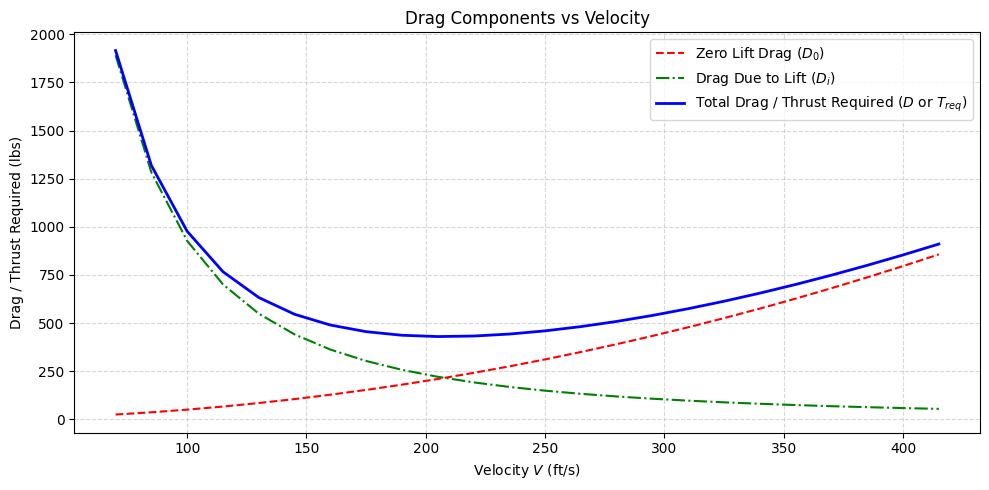

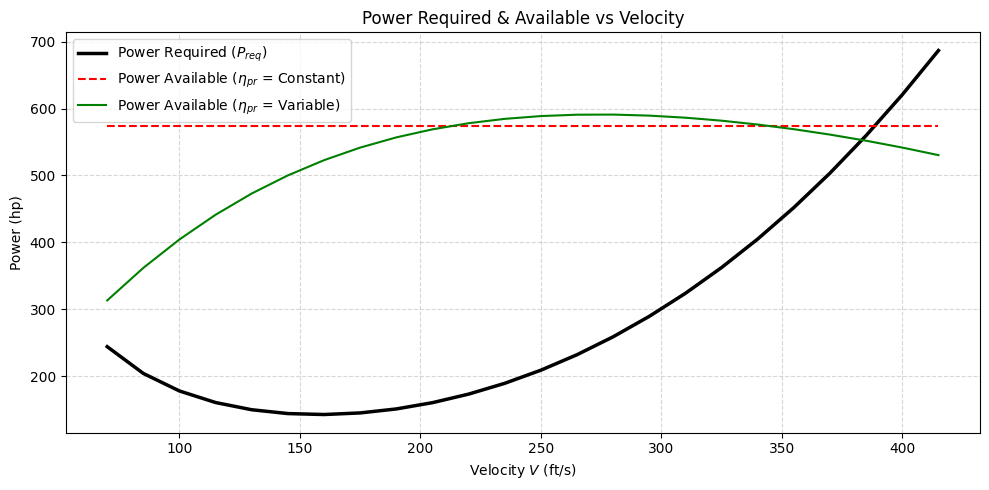


--- Enter Stall Speed & Maximum Lift Analysis Inputs ---
Maximum Airfoil Lift Coefficient (Cl_max_airfoil): 1.8
Flapped Area Sflapped (ft^2): 68
Flap Effectiveness (delta_Cl-eff): 1.3
Fowler Flap Chord Extension (C'/C): 1.2

--- Stall & Lift Analysis Results ---
Wing CLmax (Clean)          = 1.619966
Wing delta_CLmax (Flaps)     = 0.642270
Wing CLmax (Flapped)        = 2.262236
Stall Speed (Clean)         = 148.44 ft/s (87.95 kts)
Stall Speed (Flapped)       = 125.61 ft/s (74.42 kts)

--- Climb Performance Results ---
Max R/C (Constant eta_pr)    = 2034.80 fpm at V = 160.0 ft/s
Max R/C (Variable eta_pr)    = 1927.95 fpm at V = 205.0 ft/s
Max Angle (Constant eta_pr)  = 21.75 deg at V = 70.0 ft/s
Max Angle (Variable eta_pr)  = 11.28 deg at V = 130.0 ft/s


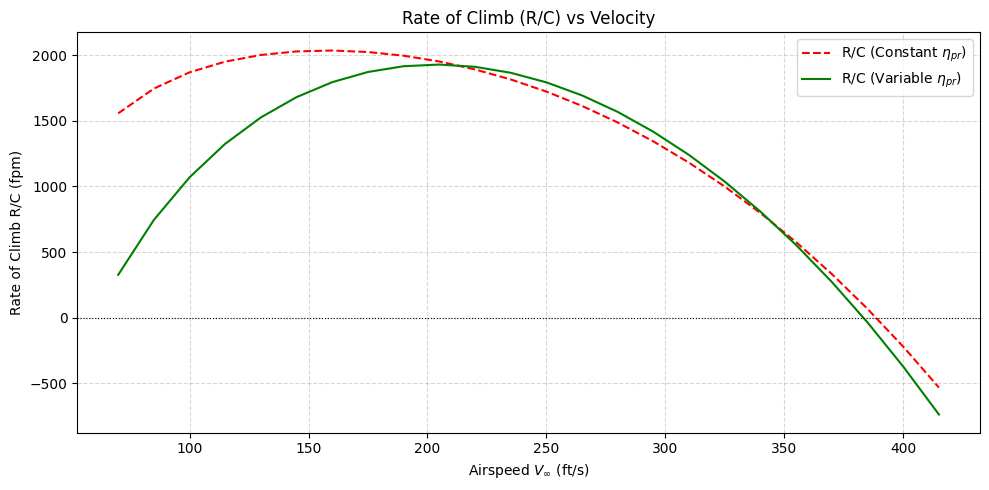

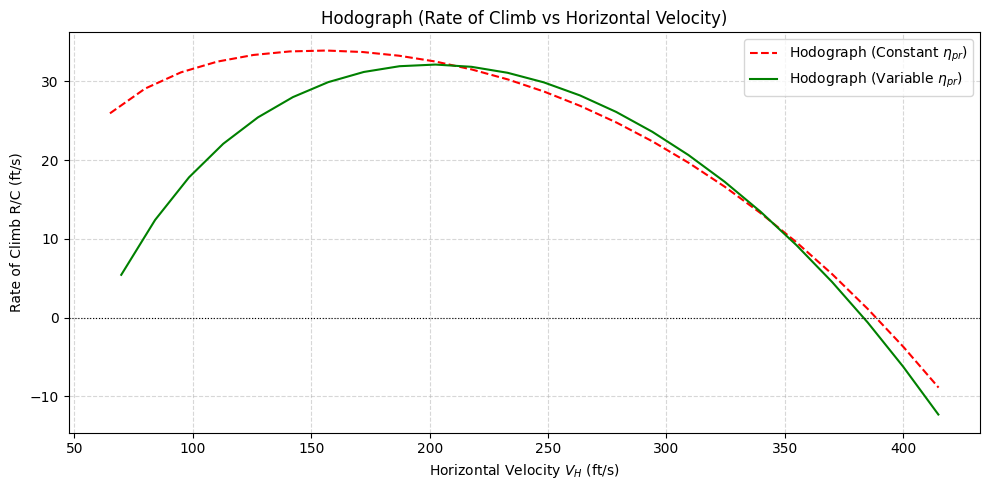


---V-n Diagram Analysis Inputs---
Maximum Limit Load Factor (nmax): 3.8
Minimum Limit Load Factor (nmin): -1.5

---V-n Diagram Results---
Corner Speed (V*) = 289.37 ft/s


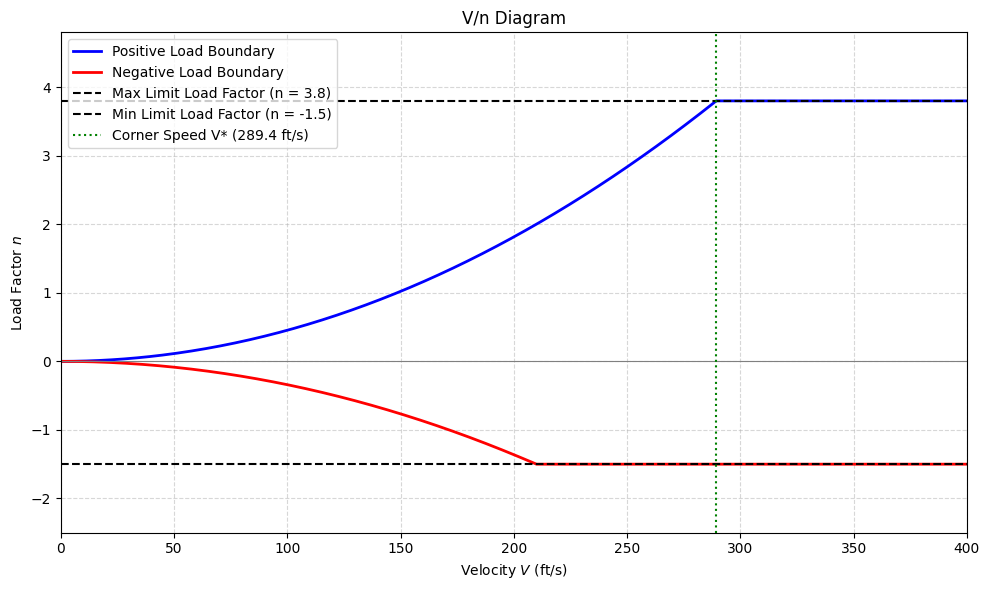

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt

# =====================================================================
# Performance I
# =====================================================================
print("--- Enter Wing Geometry & Aerodynamic Inputs ---")
b = float(input("Wing Span b (ft): "))
ct = float(input("Tip Chord ct (ft): "))
cr = float(input("Root Chord cr (ft): "))
sweep_le = float(input("Leading Edge Sweep Angle (deg): "))
a0 = float(input("Airfoil Lift Curve Slope a0 (1/deg): "))
alpha_L0 = float(input("Airfoil/Wing Zero Lift Angle (deg): "))
swet_minus_2S = float(input("Swet - 2S (ft^2): "))
Cfe = float(input("Cfe: "))

# Calculations
lam = ct / cr
S = 0.5 * (cr + ct) * b
AR = b**2 / S

def sweep_at_x(x, sweep_le_deg, AR, lam):
    term = np.tan(np.radians(sweep_le_deg))
    correction = (4 / AR) * (x * ((1 - lam) / (1 + lam)))
    return np.degrees(np.arctan(term - correction))

Lambda_025 = sweep_at_x(0.25, sweep_le, AR, lam)
Lambda_050 = sweep_at_x(0.50, sweep_le, AR, lam)
Lambda_070 = sweep_at_x(0.70, sweep_le, AR, lam)
Cmac = (2/3) * cr * ((1 + lam + lam**2) / (1 + lam))

delta = (
    (-0.401*AR + 6.6421)*lam**6
    + (1.2357*AR - 22.276)*lam**5
    + (-1.4102*AR + 29.161)*lam**4
    + (0.6687*AR - 18.733)*lam**3
    + (-0.0332*AR + 6.008)*lam**2
    + (-0.0592*AR - 0.8514)*lam
    + (0.0128*AR + 0.029)
)
e = 1 / (1 + delta)
a0_rad = a0 * (180 / math.pi)
a = a0_rad / (1 + (a0_rad / (math.pi * e * AR)))
a_deg = a * (math.pi / 180)
Swet = swet_minus_2S + 2 * S
Swet_S = Swet / S
CDo = Swet_S * Cfe
K3 = 1 / (math.pi * e * AR)
K1 = (1/3) * K3
K = K1 + K3

print(f"Planform Area S             = {S:.6f} ft²")
print(f"Aspect Ratio AR             = {AR:.6f}")
print(f"Taper Ratio \u03bb               = {lam:.6f}")
print(f"Sweep Angles: \u039b0.25 = {Lambda_025:.6f} deg, \u039b0.50 = {Lambda_050:.6f} deg, \u039b0.70 = {Lambda_070:.6f} deg")
print(f"Mean Aerodynamic Chord Cmac = {Cmac:.6f} ft")
print(f"Span Efficiency Factor e    = {e:.6f}")
print(f"Lift Curve Slope a          = {a_deg:.6f} 1/deg")
print(f"Zero-Lift Drag CDo          = {CDo:.6f}")
print(f"Induced Drag Factor K       = {K:.6f}")

# =====================================================================
# Performance II
# =====================================================================
print("\n--- Enter Steady Level Flight Analysis Inputs ---")
Ps_single = float(input("Shaft Power Ps per engine (hp): "))
# Multiply by 2 to account for 2 engines
Ps = Ps_single * 2.0
print(f"Total Shaft Power (2 engines) = {Ps:.1f} hp")

eta_pr = float(input("Constant Efficiency eta_pr: "))
W = float(input("Aircraft Weight W (lbs): "))
RPM_prop = float(input("Propeller RPM: "))
D_prop_in = float(input("Propeller Diameter D (inches): "))
rho = float(input("Air Density rho (lbs/ft³): "))

# Calculations using both new inputs & Part 1 computed values (S, CDo, K, a_deg)
D_prop = D_prop_in / 12.0
N_prop = RPM_prop / 60.0
Ps_ft_lb_s = Ps * 550.0

# Velocity Range
V_range = np.arange(70, 415 + 15, 15)

q = 0.5 * rho * V_range**2
CL = W / (q * S)
alpha_wing = (CL / a_deg) + alpha_L0

CD_zero = CDo
CD_lift = K * CL**2
CD_total = CD_zero + CD_lift

D_zero = CD_zero * q * S
D_lift = CD_lift * q * S
Thrust_req = D_zero + D_lift

Preq_ft_lb_s = Thrust_req * V_range
Preq_hp = Preq_ft_lb_s / 550.0

eta_pr_const = eta_pr
Pavail_const_hp = Ps * eta_pr_const
Pavail_const_vector = np.full_like(V_range, Pavail_const_hp)

J = V_range / (N_prop * D_prop)
eta_pr_actual = -0.1915 * J**4 + 1.0438 * J**3 - 2.4071 * J**2 + 2.414 * J - 0.0152
eta_pr_actual = np.clip(eta_pr_actual, 0.0, 1.0)
Pavail_actual_hp = Ps * eta_pr_actual

# Graphs
plt.figure(figsize=(10, 5))
plt.plot(V_range, D_zero, 'r--', label=r'Zero Lift Drag ($D_{0}$)')
plt.plot(V_range, D_lift, 'g-.', label=r'Drag Due to Lift ($D_{i}$)')
plt.plot(V_range, Thrust_req, 'b-', linewidth=2, label=r'Total Drag / Thrust Required ($D$ or $T_{req}$)')
plt.title('Drag Components vs Velocity')
plt.xlabel('Velocity $V$ (ft/s)')
plt.ylabel('Drag / Thrust Required (lbs)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(V_range, Preq_hp, 'k-', linewidth=2.5, label=r'Power Required ($P_{req}$)')
plt.plot(V_range, Pavail_const_vector, 'r--', label=r'Power Available ($\eta_{pr}$ = Constant)')
plt.plot(V_range, Pavail_actual_hp, 'g-', label=r'Power Available ($\eta_{pr}$ = Variable)')
plt.title('Power Required & Available vs Velocity')
plt.xlabel('Velocity $V$ (ft/s)')
plt.ylabel('Power (hp)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# =====================================================================
# Performance III
# =====================================================================
print("\n--- Enter Stall Speed & Maximum Lift Analysis Inputs ---")
Cl_max_airfoil = float(input("Maximum Airfoil Lift Coefficient (Cl_max_airfoil): "))
S_flapped = float(input("Flapped Area Sflapped (ft^2): "))
delta_Cl_eff = float(input("Flap Effectiveness (delta_Cl-eff): "))
C_prime_C = float(input("Fowler Flap Chord Extension (C'/C): "))

# Wing Maximum Lift Coeficcient (Clean)
CLmax_clean = 0.9 * Cl_max_airfoil * np.cos(np.radians(Lambda_025))

# Wing Maximum Lift Coefficient Due to Flaps
delta_Clmax_flap = delta_Cl_eff * C_prime_C
delta_Clmax = delta_Clmax_flap * (S_flapped / S) * np.cos(np.radians(Lambda_070))

# CLmax with Flaps
Clmax_flapped = CLmax_clean + delta_Clmax

# Stall Speeds
V_stall_clean_fps = np.sqrt((2 * W) / (rho * S * CLmax_clean))
V_stall_clean_kts = V_stall_clean_fps * 0.592484

V_stall_flapped_fps = np.sqrt((2 * W) / (rho * S * Clmax_flapped))
V_stall_flapped_kts = V_stall_flapped_fps * 0.592484

print(f"\n--- Stall & Lift Analysis Results ---")
print(f"Wing CLmax (Clean)          = {CLmax_clean:.6f}")
print(f"Wing delta_CLmax (Flaps)     = {delta_Clmax:.6f}")
print(f"Wing CLmax (Flapped)        = {Clmax_flapped:.6f}")
print(f"Stall Speed (Clean)         = {V_stall_clean_fps:.2f} ft/s ({V_stall_clean_kts:.2f} kts)")
print(f"Stall Speed (Flapped)       = {V_stall_flapped_fps:.2f} ft/s ({V_stall_flapped_kts:.2f} kts)")

#===========================================================================
# Performance IV
#===========================================================================

# Excess Power
Pexcess_const_hp = Pavail_const_vector - Preq_hp
Pexcess_const_ft_lb_s = Pexcess_const_hp * 550.0

Pexcess_actual_hp = Pavail_actual_hp - Preq_hp
Pexcess_actual_ft_lb_s = Pexcess_actual_hp * 550.0

# Rate of Climb
RC_const_fps = Pexcess_const_ft_lb_s / W
RC_actual_fps = Pexcess_actual_ft_lb_s / W

RC_const_fpm = RC_const_fps * 60.0
RC_actual_fpm = RC_actual_fps * 60.0

# Angle of Climb
theta_const_rad = np.arcsin(np.clip(RC_const_fps / V_range, -1.0, 1.0))
theta_const_deg = np.degrees(theta_const_rad)

theta_actual_rad = np.arcsin(np.clip(RC_actual_fps / V_range, -1.0, 1.0))
theta_actual_deg = np.degrees(theta_actual_rad)

# Max rates of climb and angles of climb
max_RC_const = np.max(RC_const_fpm)
idx_max_RC_const = np.argmax(RC_const_fpm)
V_max_RC_const = V_range[idx_max_RC_const]

max_RC_actual = np.max(RC_actual_fpm)
idx_max_RC_actual = np.argmax(RC_actual_fpm)
V_max_RC_actual = V_range[idx_max_RC_actual]

max_theta_const = np.max(theta_const_deg)
idx_max_theta_const = np.argmax(theta_const_deg)
V_max_theta_const = V_range[idx_max_theta_const]

max_theta_actual = np.max(theta_actual_deg)
idx_max_theta_actual = np.argmax(theta_actual_deg)
V_max_theta_actual = V_range[idx_max_theta_actual]

print("\n--- Climb Performance Results ---")
print(f"Max R/C (Constant eta_pr)    = {max_RC_const:.2f} fpm at V = {V_max_RC_const:.1f} ft/s")
print(f"Max R/C (Variable eta_pr)    = {max_RC_actual:.2f} fpm at V = {V_max_RC_actual:.1f} ft/s")
print(f"Max Angle (Constant eta_pr)  = {max_theta_const:.2f} deg at V = {V_max_theta_const:.1f} ft/s")
print(f"Max Angle (Variable eta_pr)  = {max_theta_actual:.2f} deg at V = {V_max_theta_actual:.1f} ft/s")

VH_const = V_range * np.cos(theta_const_rad)
VH_actual = V_range * np.cos(theta_actual_rad)

# R/C vs V_inf
plt.figure(figsize=(10, 5))
plt.plot(V_range, RC_const_fpm, 'r--', label=r'R/C (Constant $\eta_{pr}$)')
plt.plot(V_range, RC_actual_fpm, 'g-', label=r'R/C (Variable $\eta_{pr}$)')
plt.axhline(0, color='black', linewidth=0.8, linestyle=':')
plt.title('Rate of Climb (R/C) vs Velocity')
plt.xlabel(r'Airspeed $V_{\infty}$ (ft/s)')
plt.ylabel('Rate of Climb R/C (fpm)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Hodograph (R/C vs VH)
plt.figure(figsize=(10, 5))
plt.plot(VH_const, RC_const_fps, 'r--', label=r'Hodograph (Constant $\eta_{pr}$)')
plt.plot(VH_actual, RC_actual_fps, 'g-', label=r'Hodograph (Variable $\eta_{pr}$)')
plt.axhline(0, color='black', linewidth=0.8, linestyle=':')
plt.title('Hodograph (Rate of Climb vs Horizontal Velocity)')
plt.xlabel('Horizontal Velocity $V_H$ (ft/s)')
plt.ylabel('Rate of Climb R/C (ft/s)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

#===========================================================================
# Performance V
#===========================================================================
print("\n---V-n Diagram Analysis Inputs---")
n_max = float(input("Maximum Limit Load Factor (nmax): "))
n_min = float(input("Minimum Limit Load Factor (nmin): "))

# Inverted CLmax estimate
CLmax_inv = -0.75 * CLmax_clean

# Velocity array for plotting (0 to 400 ft/s)
V_vn = np.linspace(0, 400, 500)

# Stall limits
n_stall_pos = (0.5 * rho * V_vn**2 * S * CLmax_clean) / W
n_stall_neg = (0.5 * rho * V_vn**2 * S * CLmax_inv) / W

# Corner Speed (V*)
V_corner = np.sqrt((2 * n_max * W) / (rho * S * CLmax_clean))

n_pos_limit = np.minimum(n_stall_pos, n_max)
n_neg_limit = np.maximum(n_stall_neg, n_min)

print(f"\n---V-n Diagram Results---")
print(f"Corner Speed (V*) = {V_corner:.2f} ft/s")

# V-n Diagram
plt.figure(figsize=(10, 6))
plt.plot(V_vn, n_pos_limit, 'b-', linewidth=2, label='Positive Load Boundary')
plt.plot(V_vn, n_neg_limit, 'r-', linewidth=2, label='Negative Load Boundary')
plt.axhline(n_max, color='k', linestyle='--', label=f'Max Limit Load Factor (n = {n_max})')
plt.axhline(n_min, color='k', linestyle='--', label=f'Min Limit Load Factor (n = {n_min})')
plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(V_corner, color='g', linestyle=':', label=f'Corner Speed V* ({V_corner:.1f} ft/s)')

plt.title('V/n Diagram')
plt.xlabel('Velocity $V$ (ft/s)')
plt.ylabel('Load Factor $n$')
plt.xlim(0, 400)
plt.ylim(n_min - 1.0, n_max + 1.0)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()
